<div style="text-align: center; padding: 40px; background-color: #102a43; border-radius: 15px; border: 2px solid #243b53; box-shadow: 0 10px 20px rgba(0,0,0,0.2);">
    <h1 style="color: #ffffff; font-family: 'Arial', sans-serif; font-size: 42px; margin-bottom: 5px;">𝑷𝒂𝒏𝒅𝒂𝒔 𝑫𝒂𝒕𝒆 & 𝑻𝒊𝒎𝒆</h1>
    <h3 style="color: #9fb3c8; font-family: 'Arial', sans-serif; font-size: 24px; margin-top: 0;">𝑾𝒐𝒓𝒌𝒊𝒏𝒈 𝒘𝒊𝒕𝒉 𝑻𝒊𝒎𝒆 𝑺𝒆𝒓𝒊𝒆𝒔</h3>
    <hr style="width: 60%; border: 0.5px solid #486581; margin: 25px auto;">
    <p style="color: #ffffff; font-size: 22px; margin-bottom: 5px;">Created by: <span style="color: #33adff; font-weight: bold;">Muhammad Adnan</span></p>
    <p style="color: #9fb3c8; font-size: 14px; letter-spacing: 2px; text-transform: uppercase;">Data Analysis • Pandas • Time Series</p>
</div>

<div style="padding: 30px; background-color: #1e293b; border-radius: 15px; border: 2px solid #334155; margin-top: 20px; box-shadow: 0 6px 15px rgba(0,0,0,0.2);">
<h2 style="color: #facc15; font-size: 26px;">About This Notebook</h2>
<p style="color: #e2e8f0; font-size: 16px; line-height: 1.6;">This notebook covers the date and time tools in Pandas: <code>Timestamp</code>, <code>DatetimeIndex</code>, <code>date_range</code>, <code>to_datetime</code> and the <code>dt</code> accessor.</p>
<h3 style="color: #facc15; font-size: 22px;">Objective</h3>
<p style="color: #e2e8f0; font-size: 16px; line-height: 1.6;">To parse, create and manipulate dates so that time-based analysis becomes simple.</p>
<h3 style="color: #facc15; font-size: 22px;">Topics Covered</h3>
<ul style="color: #e2e8f0; font-size: 16px; line-height: 1.8;">
<li>Timestamp objects</li>
<li>Python datetime vs NumPy datetime64</li>
<li>DatetimeIndex</li>
<li><code>date_range()</code> and <code>to_datetime()</code></li>
<li>The <code>dt</code> accessor</li>
</ul>
</div>

<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
Imports
</div>

In [ ]:
import numpy as np
import pandas as pd

<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
Timestamp Object
</div>

Time stamps reference particular moments in time (e.g., Oct 24th, 2022 at 7:00pm)

<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
Creating Timestamp objects
</div>

In [ ]:
# creating a timestamp
type(pd.Timestamp('2026/1/27'))
pd.Timestamp('2023/1/5')

Timestamp('2023-01-05 00:00:00')

In [ ]:
# variations
pd.Timestamp('2026-1-5')
pd.Timestamp('2026, 1, 5')

Timestamp('2023-01-05 00:00:00')

In [ ]:
# only year
pd.Timestamp('2026')

Timestamp('2023-01-01 00:00:00')

In [ ]:
# using text
pd.Timestamp('5th January 2026')

Timestamp('2026-01-05 00:00:00')

In [ ]:
# providing time also
pd.Timestamp('5th January 2026 9:21AM')
# pd.Timestamp('2023/1/5/9/21')

Timestamp('2026-01-05 09:21:00')

In [ ]:
# AM and PM

In [ ]:
# using datetime.datetime object
import datetime as dt

x = pd.Timestamp(dt.datetime(2026,1,5,9,21,56))
x

Timestamp('2026-01-05 09:21:56')

In [ ]:
# fetching attributes
x.year
x.month
x.day
x.hour
x.minute
x.second

56

In [ ]:
# why separate objects to handle data and time when python already has datetime functionality?

- syntax wise datetime is very convenient
- But the performance takes a hit while working with huge data. List vs Numpy Array
- The weaknesses of Python's datetime format inspired the NumPy team to add a set of native time series data type to NumPy.
- The datetime64 dtype encodes dates as 64-bit integers, and thus allows arrays of dates to be represented very compactly.

In [ ]:
import numpy as np
date = np.array('2015-07-04', dtype=np.datetime64)
date

array('2015-07-04', dtype='datetime64[D]')

In [ ]:
date + np.arange(12)

array(['2015-07-04', '2015-07-05', '2015-07-06', '2015-07-07',
       '2015-07-08', '2015-07-09', '2015-07-10', '2015-07-11',
       '2015-07-12', '2015-07-13', '2015-07-14', '2015-07-15'],
      dtype='datetime64[D]')

- Because of the uniform type in NumPy datetime64 arrays, this type of operation can be accomplished much more quickly than if we were working directly with Python's datetime objects, especially as arrays get large

- Pandas Timestamp object combines the ease-of-use of python datetime with the efficient storage and vectorized interface of numpy.datetime64

- From a group of these Timestamp objects, Pandas can construct a DatetimeIndex that can be used to index data in a Series or DataFrame

<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
DatetimeIndex Object
</div>

A collection of pandas timestamp

In [ ]:
# from strings
type(pd.DatetimeIndex(['2023/1/1','2022/1/1','2021/1/1']))

pandas.core.indexes.datetimes.DatetimeIndex

In [ ]:
# using python datetime object
pd.DatetimeIndex([dt.datetime(2023,1,1),dt.datetime(2022,1,1),dt.datetime(2021,1,1)])

DatetimeIndex(['2023-01-01', '2022-01-01', '2021-01-01'], dtype='datetime64[ns]', freq=None)

In [ ]:
# using pd.timestamps
dt_index = pd.DatetimeIndex([pd.Timestamp(2023,1,1),pd.Timestamp(2022,1,1),pd.Timestamp(2021,1,1)])

In [ ]:
# using datatimeindex as series index

pd.Series([1,2,3],index=dt_index)

,0
2023-01-01,1
2022-01-01,2
2021-01-01,3


<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
daterange function
</div>

In [ ]:
# generate daily dates in a given range
pd.date_range(start='2023/1/5',end='2023/2/28',freq='3D')

DatetimeIndex(['2023-01-05', '2023-01-08', '2023-01-11', '2023-01-14',
               '2023-01-17', '2023-01-20', '2023-01-23', '2023-01-26',
               '2023-01-29', '2023-02-01', '2023-02-04', '2023-02-07',
               '2023-02-10', '2023-02-13', '2023-02-16', '2023-02-19',
               '2023-02-22', '2023-02-25', '2023-02-28'],
              dtype='datetime64[ns]', freq='3D')

In [ ]:
# B -> business days
pd.date_range(start='2023/1/5',end='2023/2/28',freq='B')

DatetimeIndex(['2023-01-05', '2023-01-06', '2023-01-09', '2023-01-10',
               '2023-01-11', '2023-01-12', '2023-01-13', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-23', '2023-01-24', '2023-01-25', '2023-01-26',
               '2023-01-27', '2023-01-30', '2023-01-31', '2023-02-01',
               '2023-02-02', '2023-02-03', '2023-02-06', '2023-02-07',
               '2023-02-08', '2023-02-09', '2023-02-10', '2023-02-13',
               '2023-02-14', '2023-02-15', '2023-02-16', '2023-02-17',
               '2023-02-20', '2023-02-21', '2023-02-22', '2023-02-23',
               '2023-02-24', '2023-02-27', '2023-02-28'],
              dtype='datetime64[ns]', freq='B')

In [ ]:
# W -> one week per day
pd.date_range(start='2023/1/5',end='2023/2/28',freq='W-THU')

DatetimeIndex(['2023-01-05', '2023-01-12', '2023-01-19', '2023-01-26',
               '2023-02-02', '2023-02-09', '2023-02-16', '2023-02-23'],
              dtype='datetime64[ns]', freq='W-THU')

In [ ]:
# H -> Hourly data(factor)
pd.date_range(start='2023/1/5',end='2023/2/28',freq='6H')

DatetimeIndex(['2023-01-05 00:00:00', '2023-01-05 06:00:00',
               '2023-01-05 12:00:00', '2023-01-05 18:00:00',
               '2023-01-06 00:00:00', '2023-01-06 06:00:00',
               '2023-01-06 12:00:00', '2023-01-06 18:00:00',
               '2023-01-07 00:00:00', '2023-01-07 06:00:00',
               ...
               '2023-02-25 18:00:00', '2023-02-26 00:00:00',
               '2023-02-26 06:00:00', '2023-02-26 12:00:00',
               '2023-02-26 18:00:00', '2023-02-27 00:00:00',
               '2023-02-27 06:00:00', '2023-02-27 12:00:00',
               '2023-02-27 18:00:00', '2023-02-28 00:00:00'],
              dtype='datetime64[ns]', length=217, freq='6H')

In [ ]:
# M -> Month end
pd.date_range(start='2023/1/5',end='2023/2/28',freq='M')

DatetimeIndex(['2023-01-31', '2023-02-28'], dtype='datetime64[ns]', freq='M')

In [ ]:
# MS -> Month start
pd.date_range(start='2023/1/5',end='2023/2/28',freq='MS')

DatetimeIndex(['2023-02-01'], dtype='datetime64[ns]', freq='MS')

In [ ]:
# A -> Year end
pd.date_range(start='2023/1/5',end='2030/2/28',freq='A')

DatetimeIndex(['2023-12-31', '2024-12-31', '2025-12-31', '2026-12-31',
               '2027-12-31', '2028-12-31', '2029-12-31'],
              dtype='datetime64[ns]', freq='A-DEC')

In [ ]:
# using periods(number of results)
pd.date_range(start='2023/1/5',periods=25,freq='M')

DatetimeIndex(['2023-01-31', '2023-02-28', '2023-03-31', '2023-04-30',
               '2023-05-31', '2023-06-30', '2023-07-31', '2023-08-31',
               '2023-09-30', '2023-10-31', '2023-11-30', '2023-12-31',
               '2024-01-31', '2024-02-29', '2024-03-31', '2024-04-30',
               '2024-05-31', '2024-06-30', '2024-07-31', '2024-08-31',
               '2024-09-30', '2024-10-31', '2024-11-30', '2024-12-31',
               '2025-01-31'],
              dtype='datetime64[ns]', freq='M')

<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
todatetime function
</div>

converts an existing objects to pandas timestamp/datetimeindex object

In [ ]:
# simple series example

s = pd.Series(['2023/1/1','2022/1/1','2021/1/1'])
pd.to_datetime(s).dt.day_name()

0      Sunday
1    Saturday
2      Friday
dtype: object

In [ ]:
# with errors
s = pd.Series(['2023/1/1','2022/1/1','2021/130/1'])
pd.to_datetime(s,errors='coerce').dt.month_name()

0    January
1    January
2        NaN
dtype: object

In [ ]:
df = pd.read_csv('../data/titanic.csv')

In [ ]:
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            277 non-null    datetime64[ns]
 1   Account         277 non-null    object        
 2   Category        277 non-null    object        
 3   Subcategory     0 non-null      float64       
 4   Note            273 non-null    object        
 5   INR             277 non-null    float64       
 6   Income/Expense  277 non-null    object        
 7   Note.1          0 non-null      float64       
 8   Amount          277 non-null    float64       
 9   Currency        277 non-null    object        
 10  Account.1       277 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(5)
memory usage: 23.9+ KB


<div style="font-size: 25px; font-weight: bold; color: #33adff; text-align: left; margin-top: 20px;">
dt accessor
</div>

Accessor object for datetimelike properties of the Series values.

In [ ]:
df['Date'].dt.is_quarter_start

0      False
1      False
2      False
3      False
4      False
       ...  
272    False
273    False
274    False
275    False
276    False
Name: Date, Length: 277, dtype: bool

In [ ]:
# plot graph
import matplotlib.pyplot as plt
plt.plot(df['Date'],df['INR'])

In [ ]:
# day name wise bar chart/month wise bar chart

df['day_name'] = df['Date'].dt.day_name()

In [ ]:
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday


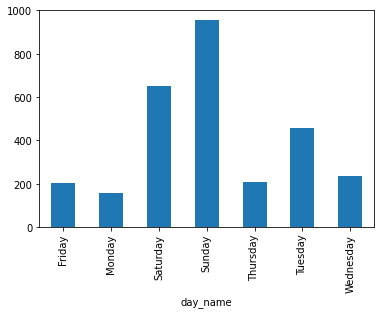

In [ ]:
df.groupby('day_name')['INR'].mean().plot(kind='bar')

In [ ]:
df['month_name'] = df['Date'].dt.month_name()

In [ ]:
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday,March
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday,March
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday,March
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday,March
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday,March


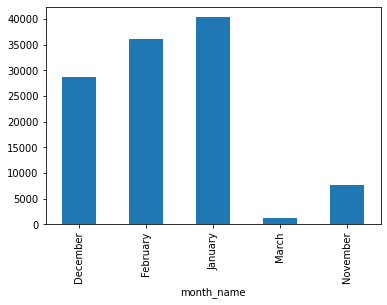

In [ ]:
df.groupby('month_name')['INR'].sum().plot(kind='bar')

In [ ]:
df[df['Date'].dt.is_month_end]

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
7,2022-02-28 11:56:00,CUB - online payment,Food,NaN,Pizza,339.15,Expense,NaN,339.15,INR,339.15,Monday,February
8,2022-02-28 11:45:00,CUB - online payment,Other,NaN,From kumara,200.00,Income,NaN,200.00,INR,200.00,Monday,February
61,2022-01-31 08:44:00,CUB - online payment,Transportation,NaN,Vnr to apk,50.00,Expense,NaN,50.00,INR,50.00,Monday,January
62,2022-01-31 08:27:00,CUB - online payment,Other,NaN,To vicky,200.00,Expense,NaN,200.00,INR,200.00,Monday,January
63,2022-01-31 08:26:00,CUB - online payment,Transportation,NaN,To ksr station,153.00,Expense,NaN,153.00,INR,153.00,Monday,January
242,2021-11-30 14:24:00,CUB - online payment,Gift,NaN,Bharath birthday,115.00,Expense,NaN,115.00,INR,115.00,Tuesday,November
243,2021-11-30 14:17:00,CUB - online payment,Food,NaN,Lunch with company,128.00,Expense,NaN,128.00,INR,128.00,Tuesday,November
244,2021-11-30 10:11:00,CUB - online payment,Food,NaN,Breakfast,70.00,Expense,NaN,70.00,INR,70.00,Tuesday,November
